In [12]:
from pathlib import Path
import json
import pandas as pd


def retrieve_songs():
    file_path = Path("../data/raw/itunes_tracks.json")

    with file_path.open("r", encoding="utf-8") as file:
        itunes_tracks = json.load(file)

    rows = []
    for song in itunes_tracks:
        results = song["response"]["results"]
        runtime = results[0].get("trackTimeMillis") if results else None

        rows.append({
            "year": song["year"],
            "title": song["title"],
            "artist": song["artist"],
            "runtime": runtime,
        })

    return pd.DataFrame(rows)


df = retrieve_songs()
df.head()

,year,title,artist,runtime
0,1970,"""Bridge Over Troubled Water""",Simon & Garfunkel,296462
1,1970,"""(They Long to Be) Close to You""",The Carpenters,276000
2,1971,"""Joy to the World""",Three Dog Night,195533
3,1971,"""Maggie May""/""Reason to Believe""",Rod Stewart,350147
4,1972,"""The First Time Ever I Saw Your Face""",Roberta Flack,259533


In [13]:
df = retrieve_songs().dropna(subset=["runtime"]).copy()

# Clean up titles and keep the first title for double A-sides.
df["title"] = df["title"].str.replace('" / "', '"/"', regex=False)
df["title"] = df["title"].str.split('"/"').str[0].str.strip('"').str.strip()
df["artist"] = df["artist"].str.strip()

# Apply your team's corrections to the iTunes matches.
df.loc[df["title"] == "Another Brick in the Wall, Part II", "runtime"] = 238947
df = df[~df["title"].isin(["You Were Meant for Me", "Poker Face"])]
df = df.drop_duplicates(subset=["title", "artist"])

# Calculate the decade and convert milliseconds to minutes.
df["decade"] = (df["year"] // 10) * 10
df["runtime_min"] = df["runtime"] / 60_000

df[["title", "decade", "runtime_min"]].head()

,title,decade,runtime_min
0,Bridge Over Troubled Water,1970,4.941033
1,(They Long to Be) Close to You,1970,4.600000
2,Joy to the World,1970,3.258883
3,Maggie May,1970,5.835783
4,The First Time Ever I Saw Your Face,1970,4.325550


In [14]:
average_duration = df.groupby("decade")["runtime_min"].mean()

average_duration.round(2)

decade
1970    4.14
1980    4.08
1990    4.44
2000    3.85
2010    3.82
2020    3.33
Name: runtime_min, dtype: float64

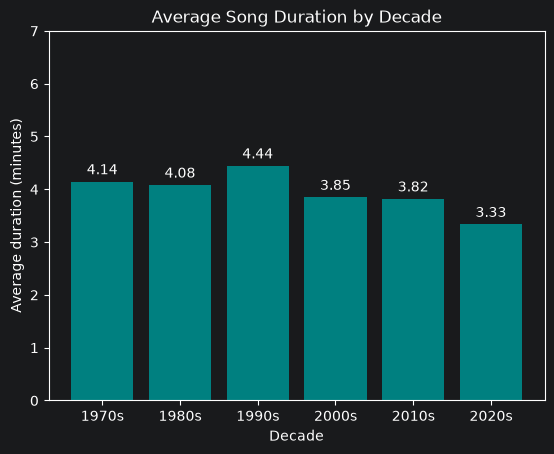

In [15]:
import matplotlib.pyplot as plt

decade_labels = [f"{decade}s" for decade in average_duration.index]
bars = plt.bar(decade_labels, average_duration.values, color="teal")

plt.xlabel("Decade")
plt.ylabel("Average duration (minutes)")
plt.title("Average Song Duration by Decade")
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.ylim(0, 7)
plt.show()

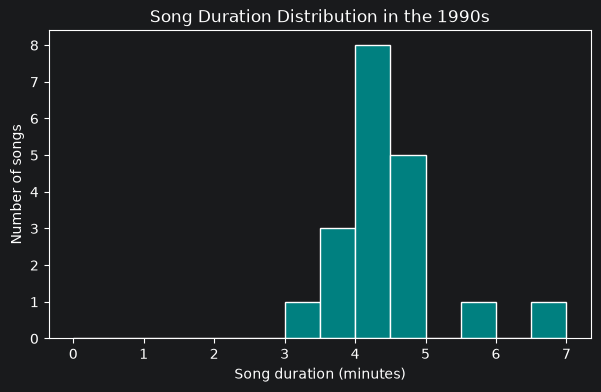

In [16]:
songs_1990s = df.loc[df["decade"] == 1990, "runtime_min"]

plt.figure(figsize=(7, 4))
plt.hist(songs_1990s, bins=[i / 2 for i in range(15)],
         color="teal", edgecolor="white")
plt.title("Song Duration Distribution in the 1990s")
plt.xlabel("Song duration (minutes)")
plt.ylabel("Number of songs")
plt.show()

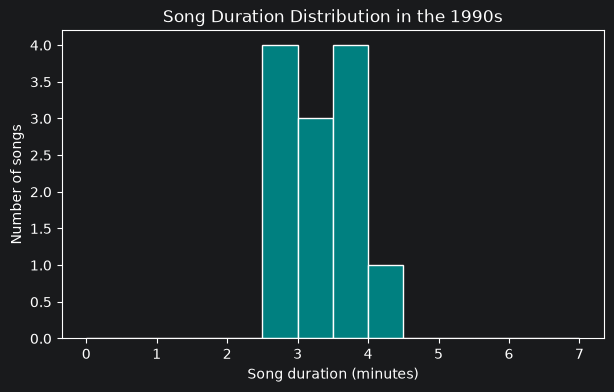

In [18]:
songs_2020s = df.loc[df["decade"] == 2020, "runtime_min"]

plt.figure(figsize=(7, 4))
plt.hist(songs_2020s, bins=[i / 2 for i in range(15)],
         color="teal", edgecolor="white")
plt.title("Song Duration Distribution in the 1990s")
plt.xlabel("Song duration (minutes)")
plt.ylabel("Number of songs")
plt.show()